# Court Document Classification: TF-IDF and Model Comparison

This notebook compares several classifiers on TF-IDF, shows the class distribution, compares metrics and builds a confusion matrix.

**Expected data:** `df2.csv` in the same folder, columns `text` and `class`, separator `;`, encoding `windows-1251`. `df2.csv` was got after "pdf_corpus_to_csv.R" script completing, search for pdf-documents on https://ras.arbitr.ru/

All models use the same TF-IDF matrix and the same train/test split, so the comparison is fair. By default there is no stemming: TF-IDF receives the raw text, removes Russian stop words and builds unigrams/bigrams. You can compare this with the original preprocessing separately.

**Speed optimizations compared with the previous version**
- TF-IDF vocabulary is capped (`MAX_FEATURES`): the previous run produced ~1.07M features, which made every model slow.
- Tree models and LightGBM get a smaller matrix (top `TREE_FEATURES` features by chi-squared, fitted on train only) instead of 1M sparse columns.
- `SGDClassifier` and the forests use several cores via threads/light workers (`N_JOBS`); Linear SVM runs in a single process on purpose, because a process pool copies the data matrix into every worker and can exhaust RAM.
- The vectorizer's `stop_words_` attribute (millions of discarded n-grams) is released after fitting, which frees a lot of memory.
- ROC-AUC is computed in one vectorised call instead of a Python loop.
- `seaborn` is removed (its import was the slow step that got interrupted); plots use `matplotlib` / scikit-learn only.
- Unused imports are removed and the stop-word list is loaded before the vectorizer is created (no `set_params` afterwards).

In [1]:
# If some libraries are missing, uncomment and run:
# %pip install pandas numpy matplotlib scikit-learn nltk

In [2]:
import gc
import time
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

# ---- Settings ----
RANDOM_STATE = 42
N_JOBS = 4                # cores for SGD / forests / LightGBM (-1 = all; lower it if RAM is tight)
MAX_FEATURES = 200_000    # TF-IDF vocabulary cap for linear / NB models (None = no cap; lower = less RAM)
TREE_FEATURES = 20_000    # features kept for tree models and LightGBM
RUN_TREE_MODELS = True    # set to False for a quick run with fast models only
DROP_DUPLICATES = False   # True removes exact duplicate texts (avoids train/test leakage)

In [3]:
# Load data (dtype=str avoids slow mixed-type inference)
docs = pd.read_csv("df2.csv", sep=";", encoding="windows-1251", dtype=str)

required_columns = {"text", "class"}
missing = required_columns - set(docs.columns)
if missing:
    raise ValueError(f"Columns not found in df2.csv: {missing}")

print("Dataset shape:", docs.shape)
display(docs.head())

# Keep only needed columns and drop rows without text or target label
docs = docs[["text", "class"]].dropna()
docs["text"] = docs["text"].str.strip()
docs["class"] = docs["class"].str.strip()
docs = docs[(docs["text"] != "") & (docs["class"] != "")].copy()

# Optional check for exact duplicate texts
print("After removing empty values:", docs.shape)
n_dupes = int(docs["text"].duplicated().sum())
print("Exact duplicate texts:", n_dupes)
if DROP_DUPLICATES and n_dupes:
    docs = docs.drop_duplicates(subset="text", keep="first").copy()
    print("After removing duplicates:", docs.shape)
print("Number of classes:", docs["class"].nunique())

Dataset shape: (28413, 3)


,doc_id,text,class
0,А01-1171-2019__20190719.pdf,Арбитражный суд Республики Адыгея Именем Росс...,1
1,А01-2550-2019__20191111.pdf,АРБИТРАЖНЫЙ СУД РЕСПУБЛИКИ АДЫГЕЯ Именем Росс...,1
2,А01-2550-2019__20191225.pdf,АРБИТРАЖНЫЙ СУД РЕСПУБЛИКИ АДЫГЕЯ Именем Росс...,1
3,А01-4303-2019__20200228.pdf,АРБИТРАЖНЫЙ СУД РЕСПУБЛИКИ АДЫГЕЯ Именем Росс...,1
4,А01-820-2019__20190702.pdf,АРБИТРАЖНЫЙ СУД РЕСПУБЛИКИ АДЫГЕЯ Именем Росс...,1


After removing empty values: (28413, 2)
Exact duplicate texts: 10
Number of classes: 15


## 1. Class distribution

The chart is sorted by document count. If there are many classes the labels may be small, so a frequency table is also shown for analysing rare classes.

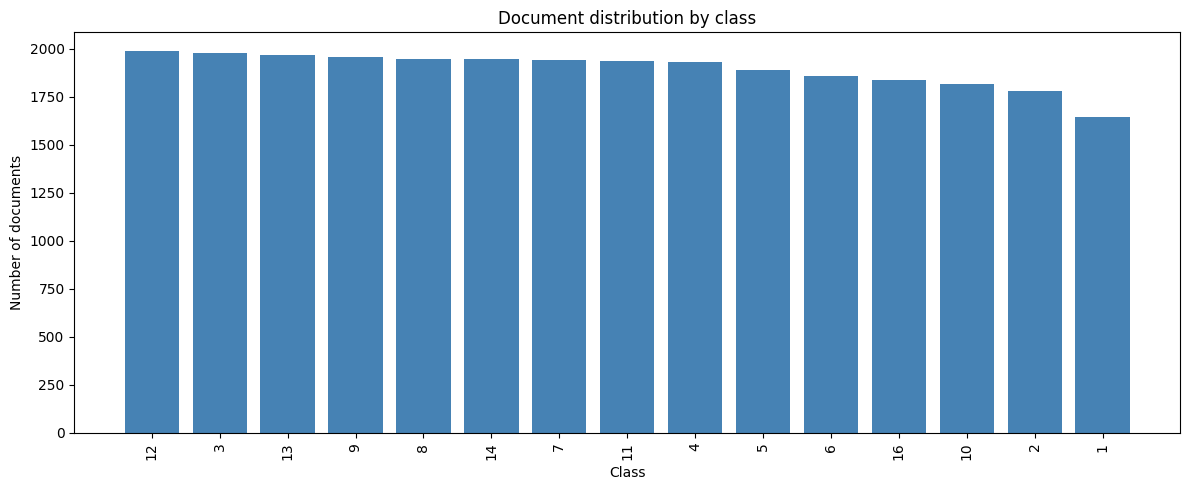

,document_count
class,
12,1986
3,1976
13,1968
9,1955
8,1947
14,1947
7,1941
11,1936
4,1933


Most frequent class: 12 - 1986
Rarest class: 1 - 1645
Classes with fewer than 5 documents: 0


In [4]:
class_counts = docs["class"].value_counts()

fig, ax = plt.subplots(figsize=(max(12, len(class_counts) * 0.35), 5))
ax.bar(class_counts.index.astype(str), class_counts.values, color="steelblue")
ax.set_ylabel("Number of documents")
ax.set_xlabel("Class")
ax.set_title("Document distribution by class")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

display(class_counts.rename("document_count").to_frame())

print("Most frequent class:", class_counts.index[0], "-", class_counts.iloc[0])
print("Rarest class:", class_counts.index[-1], "-", class_counts.iloc[-1])
print("Classes with fewer than 5 documents:", int((class_counts < 5).sum()))

## 2. Train/test split and TF-IDF

The split is stratified: it tries to preserve class proportions in both sets. A class with a single document cannot be placed in both train and test, so such rows are excluded from this experiment. If there are many such classes, decide separately how to collect more data for them.

Two feature matrices are built from the same vocabulary: the full (capped) TF-IDF matrix for linear and Naive Bayes models, and a smaller chi-squared-selected matrix for tree-based models.

In [5]:
# Stratified split needs at least 2 documents per class
class_counts = docs["class"].value_counts()
eligible_classes = class_counts[class_counts >= 2].index
excluded_classes = class_counts[class_counts < 2].index

if len(excluded_classes):
    print(f"Excluded classes with a single document: {len(excluded_classes)}")

model_docs = docs[docs["class"].isin(eligible_classes)].copy()

if model_docs["class"].nunique() < 2:
    raise ValueError("Classification needs at least two classes with enough documents.")

X_train_text, X_test_text, y_train, y_test = train_test_split(
    model_docs["text"],
    model_docs["class"],
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=model_docs["class"]
)

print("Train:", len(X_train_text), "Test:", len(X_test_text))
print("Classes in train:", y_train.nunique(), "| classes in test:", y_test.nunique())

# Optional: Russian NLTK stop words (TF-IDF still works without them)
russian_stopwords = None
try:
    import nltk
    from nltk.corpus import stopwords
    try:
        russian_stopwords = stopwords.words("russian")
    except LookupError:
        nltk.download("stopwords", quiet=True)
        russian_stopwords = stopwords.words("russian")
except Exception as e:
    print("Russian stop words not loaded; continuing without them.", e)

vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents=None,
    stop_words=russian_stopwords,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    max_features=MAX_FEATURES,
    dtype=np.float32
)

t0 = time.perf_counter()
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)
print(f"TF-IDF done in {time.perf_counter() - t0:.1f} s")

# Free memory: the vectorizer keeps every discarded n-gram in `stop_words_` (millions of strings)
vectorizer.stop_words_ = None
gc.collect()

print("TF-IDF train shape:", X_train.shape)
print("TF-IDF test shape:", X_test.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

# Smaller matrix for tree-based models (selector is fitted on train only)
selector = SelectKBest(chi2, k=min(TREE_FEATURES, X_train.shape[1])).fit(X_train, y_train)
X_train_sel = selector.transform(X_train)
X_test_sel = selector.transform(X_test)
print("Selected-feature matrix shape (tree models):", X_train_sel.shape)

Train: 21309 Test: 7104
Classes in train: 15 | classes in test: 15
TF-IDF done in 314.3 s
TF-IDF train shape: (21309, 200000)
TF-IDF test shape: (7104, 200000)
Vocabulary size: 200000
Selected-feature matrix shape (tree models): (21309, 20000)


## 3. Training and comparing models

We compare linear models, Naive Bayes classifiers and several trees/ensembles. For sparse TF-IDF features, Linear SVM, Logistic Regression, ComplementNB and SGDClassifier are usually the most useful. Trees are included for comparison; they use the reduced feature matrix to keep training time reasonable.

Multiclass ROC-AUC is computed as macro One-vs-Rest from class scores. Models without `predict_proba` use `decision_function`. If the metric cannot be computed on this split, the table shows `NaN`.

In [6]:
# Each entry: name -> (estimator, feature set: "full" or "selected")
models = {
    "Logistic Regression": (LogisticRegression(
        max_iter=300, class_weight="balanced", random_state=RANDOM_STATE
    ), "full"),
    # Single process on purpose: a process pool would copy the matrix into every worker (out-of-memory)
    "Linear SVM": (LinearSVC(
        dual=True, class_weight="balanced", random_state=RANDOM_STATE
    ), "full"),
    "MultinomialNB": (MultinomialNB(), "full"),
    "ComplementNB": (ComplementNB(), "full"),
    "SGDClassifier (hinge)": (SGDClassifier(
        loss="hinge", max_iter=1000, tol=1e-3, class_weight="balanced",
        n_jobs=N_JOBS, random_state=RANDOM_STATE
    ), "full"),
}

if RUN_TREE_MODELS:
    models.update({
        "Decision Tree": (DecisionTreeClassifier(
            class_weight="balanced", random_state=RANDOM_STATE
        ), "selected"),
        "Random Forest": (RandomForestClassifier(
            n_estimators=200, class_weight="balanced",
            n_jobs=N_JOBS, random_state=RANDOM_STATE
        ), "selected"),
        "Extra Trees": (ExtraTreesClassifier(
            n_estimators=200, class_weight="balanced",
            n_jobs=N_JOBS, random_state=RANDOM_STATE
        ), "selected"),
    })
    # LightGBM is added only if the library is installed
    try:
        from lightgbm import LGBMClassifier
        models["LightGBM"] = (LGBMClassifier(
            objective="multiclass",
            n_estimators=200,
            colsample_bytree=0.3,
            n_jobs=N_JOBS,
            verbosity=-1,
            random_state=RANDOM_STATE
        ), "selected")
    except ImportError:
        print("LightGBM is not installed - model skipped. Optional: %pip install lightgbm")

features = {
    "full": (X_train, X_test),
    "selected": (X_train_sel, X_test_sel),
}

def get_class_scores(model, X):
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X)
    elif hasattr(model, "decision_function"):
        scores = model.decision_function(X)
    else:
        return None
    scores = np.asarray(scores)
    if scores.ndim == 1:
        # Binary case: turn a single decision score into two columns
        scores = np.column_stack([-scores, scores])
    return scores

def macro_ovr_auc(model, X, y_true):
    """Macro one-vs-rest ROC-AUC in one vectorised call (works with any class scores)."""
    scores = get_class_scores(model, X)
    if scores is None:
        return np.nan
    classes = list(model.classes_)
    y_bin = label_binarize(y_true, classes=classes)
    if y_bin.shape[1] == 1:
        y_bin = np.hstack([1 - y_bin, y_bin])
    if scores.shape[1] != y_bin.shape[1]:
        return np.nan
    return float(roc_auc_score(y_bin, scores, average="macro"))

results = []
fitted_models = {}
predictions = {}

for name, (model, feature_set) in models.items():
    Xtr, Xte = features[feature_set]
    print(f"Training: {name} ({feature_set} features, {Xtr.shape[1]} columns) ...")
    try:
        start_fit = time.perf_counter()
        model.fit(Xtr, y_train)
        fit_seconds = time.perf_counter() - start_fit

        start_pred = time.perf_counter()
        y_pred = model.predict(Xte)
        predict_seconds = time.perf_counter() - start_pred

        try:
            roc_auc_macro_ovr = macro_ovr_auc(model, Xte, y_test)
        except Exception as auc_error:
            print(f"  ROC-AUC not computed: {auc_error}")
            roc_auc_macro_ovr = np.nan

        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
            "Recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
            "F1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
            "F1_weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
            "ROC_AUC_macro_OVR": roc_auc_macro_ovr,
            "Fit_seconds": fit_seconds,
            "Predict_seconds": predict_seconds,
        })
        fitted_models[name] = model
        predictions[name] = y_pred
        print(f"  done in {fit_seconds:.1f} s")

    except Exception as e:
        print(f"  Model {name} failed with an error: {e}")

results_df = pd.DataFrame(results).sort_values(
    ["F1_macro", "F1_weighted"], ascending=False
).reset_index(drop=True)

display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision_macro": "{:.4f}",
    "Recall_macro": "{:.4f}",
    "F1_macro": "{:.4f}",
    "F1_weighted": "{:.4f}",
    "ROC_AUC_macro_OVR": "{:.4f}",
    "Fit_seconds": "{:.2f}",
    "Predict_seconds": "{:.2f}",
}))

Training: Logistic Regression (full features, 200000 columns) ...
  done in 576.0 s
Training: Linear SVM (full features, 200000 columns) ...
  done in 71.1 s
Training: MultinomialNB (full features, 200000 columns) ...
  done in 3.4 s
Training: ComplementNB (full features, 200000 columns) ...
  done in 3.4 s
Training: SGDClassifier (hinge) (full features, 200000 columns) ...
  done in 15.3 s
Training: Decision Tree (selected features, 20000 columns) ...
  done in 180.8 s
Training: Random Forest (selected features, 20000 columns) ...
  done in 308.2 s
Training: Extra Trees (selected features, 20000 columns) ...
  done in 233.4 s
Training: LightGBM (selected features, 20000 columns) ...
  done in 1906.3 s


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,ROC_AUC_macro_OVR,Fit_seconds,Predict_seconds
0,LightGBM,0.8805,0.8828,0.8804,0.8812,0.8809,0.9906,1906.30,4.33
1,Linear SVM,0.8747,0.8746,0.8746,0.8735,0.8732,0.9864,71.14,1.45
2,SGDClassifier (hinge),0.8519,0.8520,0.8522,0.8483,0.8478,0.9817,15.33,0.88
3,Extra Trees,0.8401,0.8422,0.8402,0.8399,0.8393,0.9813,233.43,4.13
4,Random Forest,0.8360,0.8391,0.8361,0.8359,0.8353,0.9808,308.17,2.48
5,Logistic Regression,0.8335,0.8367,0.8338,0.8340,0.8333,0.9824,575.99,1.80
6,ComplementNB,0.7520,0.7602,0.7540,0.7436,0.7417,0.9614,3.43,1.15
7,Decision Tree,0.7258,0.7281,0.7263,0.7269,0.7261,0.8535,180.81,0.16
8,MultinomialNB,0.7095,0.7291,0.7120,0.7072,0.7043,0.9490,3.43,1.13


## 4. Metric comparison chart

One chart compares Accuracy, Macro Precision, Macro Recall, Macro F1, Weighted F1 and ROC-AUC. Fit and prediction times stay in the table above because their scales differ.

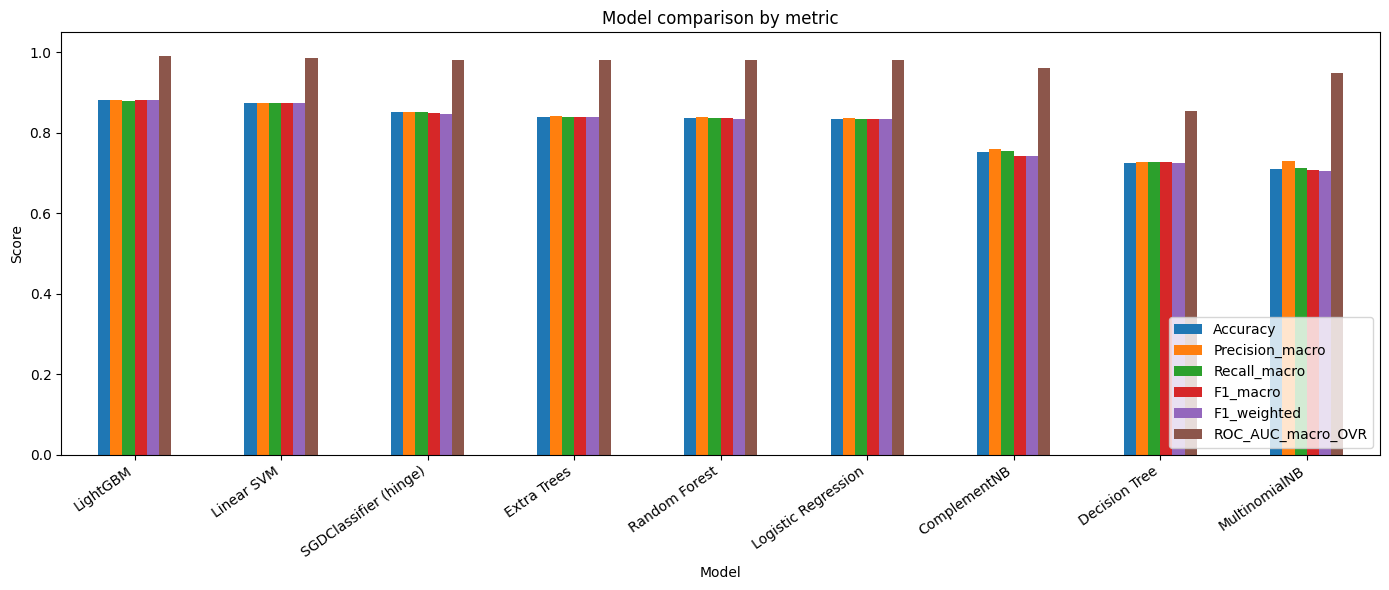

In [7]:
metric_columns = [
    "Accuracy", "Precision_macro", "Recall_macro",
    "F1_macro", "F1_weighted", "ROC_AUC_macro_OVR"
]
plot_results = results_df.set_index("Model")[metric_columns]

ax = plot_results.plot(kind="bar", figsize=(14, 6))
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_title("Model comparison by metric")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5. Detailed report and confusion matrix for the best model

The best model is chosen by Macro F1. With many classes the full confusion matrix can be too large to read, so:
- the full report and the full matrix are saved to files;
- the plot shows the most frequent classes in the test set;
- if needed, increase `TOP_N` or build the matrix only for the classes you care about.

Best model by Macro F1: LightGBM
              precision    recall  f1-score   support

           1       0.87      0.81      0.84       411
          10       0.96      0.96      0.96       453
          11       0.93      0.90      0.92       484
          12       0.78      0.84      0.81       497
          13       0.86      0.90      0.88       492
          14       0.72      0.70      0.71       487
          16       0.96      0.93      0.94       459
           2       0.85      0.86      0.85       445
           3       0.86      0.89      0.88       494
           4       0.91      0.88      0.90       483
           5       0.81      0.86      0.83       473
           6       0.98      0.94      0.96       465
           7       0.94      0.91      0.92       485
           8       0.91      0.91      0.91       487
           9       0.93      0.90      0.91       489

    accuracy                           0.88      7104
   macro avg       0.88      0.88      0.88    

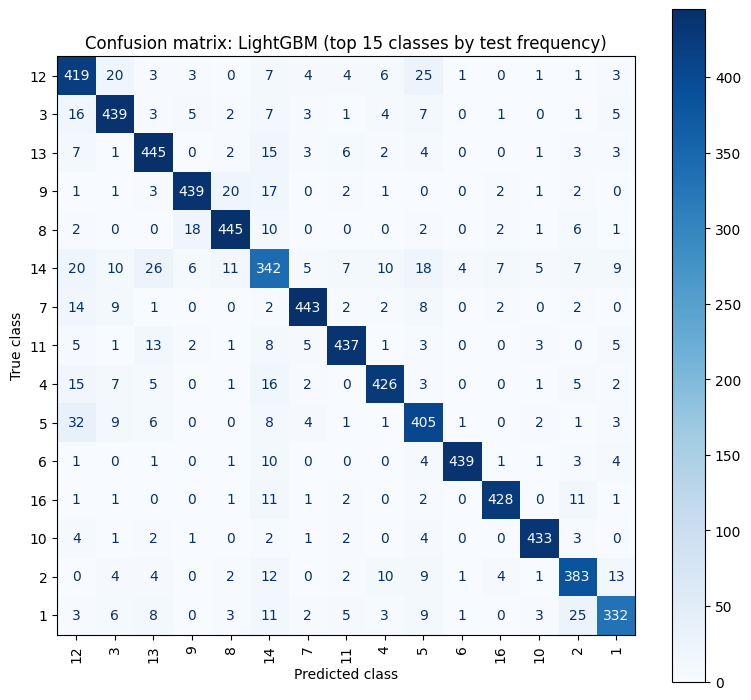

Full matrix saved to confusion_matrix_full.csv
Report saved to classification_report_best_model.csv


In [8]:
if results_df.empty:
    raise RuntimeError("No model finished successfully.")

best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_pred = predictions[best_name]

print("Best model by Macro F1:", best_name)
print(classification_report(y_test, best_pred, zero_division=0))

report_dict = classification_report(y_test, best_pred, output_dict=True, zero_division=0)
pd.DataFrame(report_dict).transpose().to_csv("classification_report_best_model.csv", encoding="utf-8-sig")

labels = list(best_model.classes_)
cm = confusion_matrix(y_test, best_pred, labels=labels)
pd.DataFrame(cm, index=labels, columns=labels).to_csv("confusion_matrix_full.csv", encoding="utf-8-sig")

TOP_N = 25
top_classes = y_test.value_counts().head(TOP_N).index.tolist()

side = max(8, len(top_classes) * 0.45)
fig, ax = plt.subplots(figsize=(side, side * 0.9))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, labels=top_classes, ax=ax, cmap="Blues",
    xticks_rotation=90, include_values=len(top_classes) <= 20, values_format="d"
)
ax.set_title(f"Confusion matrix: {best_name} (top {len(top_classes)} classes by test frequency)")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
plt.tight_layout()
plt.show()

print("Full matrix saved to confusion_matrix_full.csv")
print("Report saved to classification_report_best_model.csv")

## 6. Misclassified documents for manual analysis

The table shows examples where the predicted class differs from the true class. It helps find the classes the model confuses most often and check whether errors come from labelling quality or overlapping categories.

In [9]:
error_analysis = pd.DataFrame({
    "text": X_test_text.to_numpy(),
    "true_class": y_test.to_numpy(),
    "predicted_class": best_pred
})
error_analysis = error_analysis[error_analysis["true_class"] != error_analysis["predicted_class"]].copy()
print("Misclassified predictions:", len(error_analysis), "out of", len(y_test))
display(error_analysis.head(20))
error_analysis.to_csv("misclassified_documents.csv", index=False, encoding="utf-8-sig")

Misclassified predictions: 849 out of 7104


,text,true_class,predicted_class
0,125526104513 АРБИТРАЖНЫЙ СУД ГОРОДА МОСКВЫ 115...,7,5
3,444420192284624 Арбитражный суд города СанктПе...,1,10
6,11572020826393 АРБИТРАЖНЫЙ СУД ЯРОСЛАВСКОЙ ОБЛ...,7,5
12,90000103325823130 АРБИТРАЖНЫЙ СУД ГОРОДА МОСКВ...,8,2
17,6032019355472 АРБИТРАЖНЫЙ СУД НОВГОРОДСКОЙ ОБЛ...,2,5
22,11111114824163483 АРБИТРАЖНЫЙ СУД ИРКУТСКОЙ ОБ...,5,12
29,546326009907 АРБИТРАЖНЫЙ СУД ГОРОДА МОСКВЫ 115...,7,14
32,13725778338 АРБИТРАЖНЫЙ СУД ГОРОДА МОСКВЫ 1152...,8,2
35,404120197658092 Арбитражный суд города СанктПе...,12,2
48,107566820004 АРБИТРАЖНЫЙ СУД РОСТОВСКОЙ ОБЛАСТ...,14,3


## Notes on interpreting the results

- **Macro F1** is especially useful when quality on rare classes matters.
- **Weighted F1** accounts for class size and can be high even when results on rare categories are weak.
- **ROC-AUC OVR** measures how well the model ranks documents for each class; it is not the same as the accuracy of the final class choice. For multiclass problems use AUC together with F1 and the confusion matrix.
- Comparing models is only valid on the same test set. For the final choice of hyperparameters, use cross-validation on train and keep the test set for the final evaluation.
- With hundreds of classes, TF-IDF + linear models are usually a good baseline. Trees/ensembles are included for experimentation but may need more memory and time.
- If documents from the same court case are similar to each other, a random split can overestimate quality. If a case identifier is available, consider a group split by case.
- Tree models use only the top `TREE_FEATURES` chi-squared features, so their scores reflect that reduction; raise `TREE_FEATURES` if you want a closer comparison (at the cost of speed).